In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# ====== UBAH BAGIAN INI ======
DATA_DIR   = "/content/dataset"   # harus berisi folder train/ val/ test/, tiap folder berisi subfolder per kelas
BACKBONE   = "efficientnetb0"     # pilihan: efficientnetb0 | resnet50 | mobilenetv2 | xception
IMG_SIZE   = (224, 224)           # xception idealnya (299, 299)
BATCH_SIZE = 32
EPOCHS_HEAD = 10
EPOCHS_FT   = 10
SEED = 42
# =============================

tf.keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "https://drive.google.com/drive/folders/1YXBBtgCJevSsN2AaOdg30v4SoY8l5S38?usp=sharing"

Mounted at /content/drive


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'Dataset_Chest X-Ray (Pneumonia)', '42324037_Ruben Sibarani_sbd', 'w11s0201_pam_42324037.zip', 'w11s0202_pam_42324037.zip', 'Google AI Studio', 'inbound55850476232266282.pdf', 'dataset_cabai.zip', 'cabai_v1']


In [9]:
DATA_DIR = "/content/drive/MyDrive/Dataset_Chest X-Ray (Pneumonia)/chest_xray"   # ganti sesuai hasil di atas
print(os.listdir(DATA_DIR))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Dataset_Chest X-Ray (Pneumonia)/chest_xray'

In [8]:
import os
DATA_DIR = "/content/drive/MyDrive/Dataset_Chest X-Ray (Pneumonia)"

for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} file)")

Dataset_Chest X-Ray (Pneumonia)/  (1 file)


In [10]:
from google.colab import drive
drive.mount("/content/drive")

import os

# 1. Isi My Drive (repr menampilkan spasi/karakter tersembunyi)
print("Isi MyDrive:")
for name in os.listdir("/content/drive/MyDrive"):
    print("  ", repr(name))

# 2. Cari folder bernama train/test/val di seluruh Drive
print("\nFolder train/test/val yang ditemukan:")
for root, dirs, files in os.walk("/content/drive"):
    for d in dirs:
        if d.lower() in ("train", "training", "test", "val", "validation"):
            print("  ", os.path.join(root, d))
    if root.count(os.sep) > 7:   # batasi kedalaman agar tidak lama
        dirs.clear()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Isi MyDrive:
   'Colab Notebooks'
   'Dataset_Chest X-Ray (Pneumonia)'
   '42324037_Ruben Sibarani_sbd'
   'w11s0201_pam_42324037.zip'
   'w11s0202_pam_42324037.zip'
   'Google AI Studio'
   'inbound55850476232266282.pdf'
   'dataset_cabai.zip'
   'cabai_v1'

Folder train/test/val yang ditemukan:


In [11]:
import os
DATA_DIR = "/content/drive/MyDrive/Dataset_Chest X-Ray (Pneumonia)"

print("Isi folder dataset:")
for name in os.listdir(DATA_DIR):
    full = os.path.join(DATA_DIR, name)
    tipe = "FOLDER" if os.path.isdir(full) else "FILE"
    print(f"  [{tipe}] {name!r}")

Isi folder dataset:
  [FILE] 'archive (7).zip'


In [12]:
import zipfile, os

ZIP_PATH = "/content/drive/MyDrive/Dataset_Chest X-Ray (Pneumonia)/archive (7).zip"
EXTRACT_TO = "/content/dataset"

os.makedirs(EXTRACT_TO, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_TO)
print("Selesai diekstrak")

Selesai diekstrak


In [13]:
for root, dirs, files in os.walk(EXTRACT_TO):
    depth = root[len(EXTRACT_TO):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} file)")

dataset/  (0 file)
  chest_xray/  (0 file)
    chest_xray/  (1 file)
      train/  (1 file)
      test/  (1 file)
      val/  (1 file)
    __MACOSX/  (1 file)
      chest_xray/  (3 file)
    train/  (0 file)
      PNEUMONIA/  (3875 file)
      NORMAL/  (1341 file)
    test/  (0 file)
      PNEUMONIA/  (390 file)
      NORMAL/  (234 file)
    val/  (0 file)
      PNEUMONIA/  (8 file)
      NORMAL/  (8 file)


In [14]:
import os, re, shutil
from sklearn.model_selection import GroupShuffleSplit

SRC = "/content/dataset/chest_xray"
DST = "/content/data_split"
classes = ["NORMAL", "PNEUMONIA"]

def patient_id(fname):
    m = re.match(r"(person\d+)", fname)       # person123_bacteria_456.jpeg
    if m: return m.group(1)
    m = re.search(r"(IM-\d+)", fname)         # IM-0115-0001.jpeg
    if m: return m.group(1)
    return fname

# kumpulkan train + val asli
items = []
for split in ["train", "val"]:
    for c in classes:
        d = os.path.join(SRC, split, c)
        for f in os.listdir(d):
            if f.lower().endswith((".jpeg", ".jpg", ".png")):
                items.append((os.path.join(d, f), c, patient_id(f)))

# bagi 85/15 berdasarkan pasien
groups = [g for _, _, g in items]
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr_idx, va_idx = next(gss.split(items, groups=groups))

def copy_items(idx, split):
    for i in idx:
        path, c, _ = items[i]
        out = os.path.join(DST, split, c)
        os.makedirs(out, exist_ok=True)
        shutil.copy2(path, out)

shutil.rmtree(DST, ignore_errors=True)
copy_items(tr_idx, "train")
copy_items(va_idx, "val")
shutil.copytree(os.path.join(SRC, "test"), os.path.join(DST, "test"))

# cek hasil
for s in ["train", "val", "test"]:
    print(s, {c: len(os.listdir(os.path.join(DST, s, c))) for c in classes})

train {'NORMAL': 1129, 'PNEUMONIA': 3291}
val {'NORMAL': 220, 'PNEUMONIA': 592}
test {'NORMAL': 234, 'PNEUMONIA': 390}


In [15]:
import os, json, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# ====== UBAH BAGIAN INI ======
DATA_DIR   = "/content/dataset"   # harus berisi folder train/ val/ test/, tiap folder berisi subfolder per kelas
BACKBONE   = "efficientnetb0"     # pilihan: efficientnetb0 | resnet50 | mobilenetv2 | xception
IMG_SIZE   = (224, 224)           # xception idealnya (299, 299)
BATCH_SIZE = 32
EPOCHS_HEAD = 10
EPOCHS_FT   = 10
SEED = 42
# =============================

tf.keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/data_split"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_DIR, split),
        image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="int", shuffle=shuffle, seed=SEED
    )

train_ds = load("train", True)
val_ds   = load("val", False)
test_ds  = load("test", False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Kelas:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 4420 files belonging to 2 classes.
Found 812 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Kelas: ['NORMAL', 'PNEUMONIA']


train {'NORMAL': 1129, 'PNEUMONIA': 3291}
val {'NORMAL': 220, 'PNEUMONIA': 592}
test {'NORMAL': 234, 'PNEUMONIA': 390}
Class weight: {0: 1.95748449955713, 1: 0.6715284108173807}


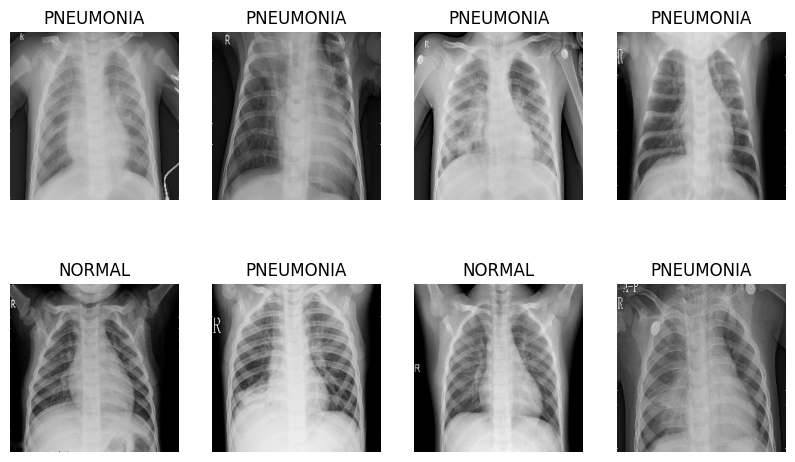

In [18]:
def count_per_class(split):
    d = os.path.join(DATA_DIR, split)
    return {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))}

for s in ["train", "val", "test"]:
    print(s, count_per_class(s))

counts = count_per_class("train")
total = sum(counts.values())
class_weight = {i: total / (NUM_CLASSES * counts[c]) for i, c in enumerate(class_names)}
print("Class weight:", class_weight)

# contoh gambar
plt.figure(figsize=(10, 6))
for imgs, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [19]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augment")

BACKBONES = {
    "efficientnetb0": (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input),
    "resnet50":       (tf.keras.applications.ResNet50,       tf.keras.applications.resnet50.preprocess_input),
    "mobilenetv2":    (tf.keras.applications.MobileNetV2,    tf.keras.applications.mobilenet_v2.preprocess_input),
    "xception":       (tf.keras.applications.Xception,       tf.keras.applications.xception.preprocess_input),
}

def build_model(name):
    ctor, preprocess = BACKBONES[name]
    base = ctor(weights="imagenet", include_top=False, input_shape=IMG_SIZE + (3,))
    base.trainable = False

    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)              # augmentasi hanya aktif saat training
    x = preprocess(x)                # preprocessing ikut tersimpan di dalam model
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    if NUM_CLASSES == 2:
        outputs = layers.Dense(1, activation="sigmoid")(x)
    else:
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inputs, outputs), base

model, base = build_model(BACKBONE)

def compile_model(lr):
    if NUM_CLASSES == 2:
        loss = "binary_crossentropy"
        metrics = ["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Recall(name="recall")]
    else:
        loss = "sparse_categorical_crossentropy"
        metrics = ["accuracy"]
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss=loss, metrics=metrics)

compile_model(1e-3)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [20]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                  class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 64s 341ms/step - accuracy: 0.8256 - auc: 0.9163 - loss: 0.3971 - recall: 0.8140 - val_accuracy: 0.8756 - val_auc: 0.9716 - val_loss: 0.3060 - val_recall: 0.8412 - learning_rate: 0.0010
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 296ms/step - accuracy: 0.8932 - auc: 0.9644 - loss: 0.2560 - recall: 0.8839 - val_accuracy: 0.9089 - val_auc: 0.9779 - val_loss: 0.2311 - val_recall: 0.8936 - learning_rate: 0.0010
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 33s 237ms/step - accuracy: 0.9109 - auc: 0.9743 - loss: 0.2154 - recall: 0.9031 - val_accuracy: 0.9212 - val_auc: 0.9817 - val_loss: 0.1976 - val_recall: 0.9139 - learning_rate: 0.0010
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 33s 236ms/step - accuracy: 0.9176 - auc: 0.9783 - loss: 0.1979 - recall: 0.9113 - val_accuracy: 0.9261 - val_auc: 0.9834 - val_loss: 0.1975 - val_recall: 0.9088 - learning_rate: 0.0010
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 34s 244ms/step - accuracy: 0.9213 - auc: 0.9794 - loss: 0.18

In [21]:
base.trainable = True
for layer in base.layers[:-30]:     # buka hanya 30 layer terakhir
    layer.trainable = False
# BatchNorm tetap beku agar stabil
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(1e-5)                 # learning rate kecil

hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
                  class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 48s 270ms/step - accuracy: 0.9326 - auc: 0.9822 - loss: 0.1694 - recall: 0.9246 - val_accuracy: 0.9372 - val_auc: 0.9871 - val_loss: 0.1642 - val_recall: 0.9240 - learning_rate: 1.0000e-05
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 37s 241ms/step - accuracy: 0.9362 - auc: 0.9858 - loss: 0.1521 - recall: 0.9307 - val_accuracy: 0.9261 - val_auc: 0.9888 - val_loss: 0.1839 - val_recall: 0.9037 - learning_rate: 1.0000e-05
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 35s 251ms/step - accuracy: 0.9330 - auc: 0.9855 - loss: 0.1520 - recall: 0.9256 - val_accuracy: 0.9421 - val_auc: 0.9898 - val_loss: 0.1467 - val_recall: 0.9307 - learning_rate: 1.0000e-05
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 45s 277ms/step - accuracy: 0.9466 - auc: 0.9889 - loss: 0.1333 - recall: 0.9429 - val_accuracy: 0.9421 - val_auc: 0.9907 - val_loss: 0.1514 - val_recall: 0.9257 - learning_rate: 1.0000e-05
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 33s 236ms/step - accuracy: 0.9419 - auc: 0.9

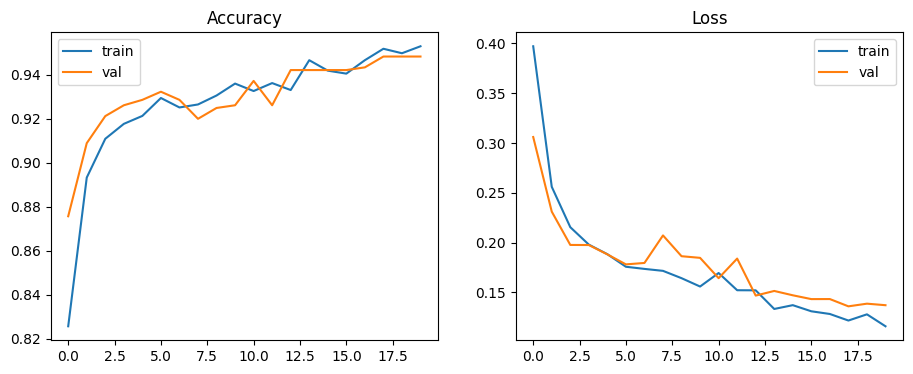

In [22]:
def plot_history(*hists):
    acc  = sum([h.history["accuracy"] for h in hists], [])
    vacc = sum([h.history["val_accuracy"] for h in hists], [])
    loss = sum([h.history["loss"] for h in hists], [])
    vloss = sum([h.history["val_loss"] for h in hists], [])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="val"); ax[1].set_title("Loss"); ax[1].legend()
    plt.show()

plot_history(hist1, hist2)

20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 335ms/step
AUC: 0.9531339031339031


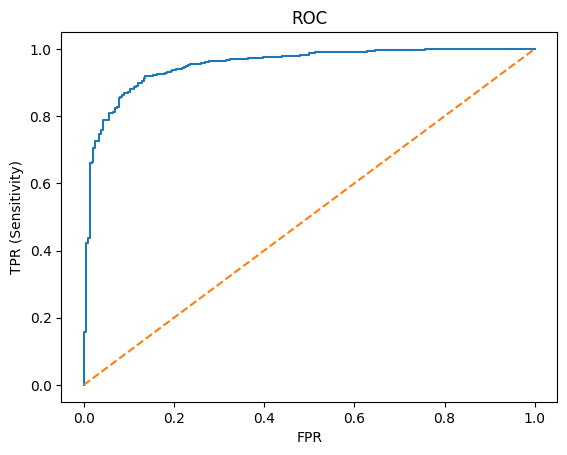

              precision    recall  f1-score   support

      NORMAL     0.9213    0.7009    0.7961       234
   PNEUMONIA     0.8430    0.9641    0.8995       390

    accuracy                         0.8654       624
   macro avg     0.8822    0.8325    0.8478       624
weighted avg     0.8724    0.8654    0.8607       624

[[164  70]
 [ 14 376]]


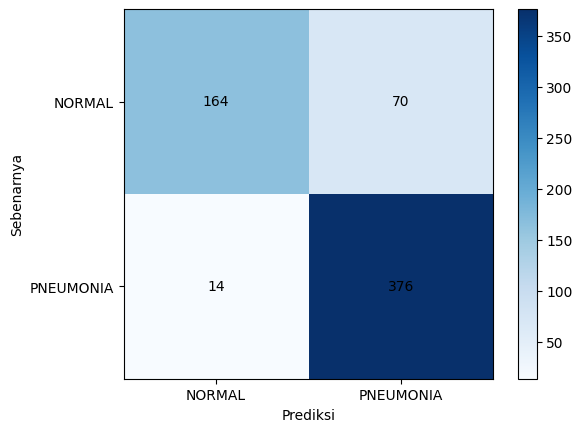

Sensitivity: 0.9641025641025641
Specificity: 0.7008547008547008


In [23]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)

if NUM_CLASSES == 2:
    y_prob = y_prob.ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    print("AUC:", roc_auc_score(y_true, y_prob))
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("FPR"); plt.ylabel("TPR (Sensitivity)"); plt.title("ROC"); plt.show()
else:
    y_pred = y_prob.argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
print(cm)
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.show()

if NUM_CLASSES == 2:
    tn, fp, fn, tp = cm.ravel()
    print("Sensitivity:", tp / (tp + fn))
    print("Specificity:", tn / (tn + fp))

In [24]:
def gradcam(model, img_array, last_conv_name=None):
    """img_array: gambar mentah shape (H, W, 3), nilai 0-255"""
    base_model = model.get_layer(base.name)
    if last_conv_name is None:
        last_conv_name = [l.name for l in base_model.layers if isinstance(l, layers.Conv2D)][-1]

    # model dari input backbone -> (feature map terakhir, output backbone)
    feat_model = tf.keras.Model(base_model.input,
                                [base_model.get_layer(last_conv_name).output, base_model.output])

    # bagian setelah backbone (pooling, dropout, dense)
    head_input = tf.keras.Input(shape=base_model.output.shape[1:])
    x = head_input
    after = False
    for l in model.layers:
        if after: x = l(x)
        if l.name == base.name: after = True
    head_model = tf.keras.Model(head_input, x)

    ctor, preprocess = BACKBONES[BACKBONE]
    x = preprocess(tf.cast(img_array[None, ...], tf.float32))
    with tf.GradientTape() as tape:
        conv_out, bb_out = feat_model(x)
        tape.watch(conv_out)
        _, bb_out = feat_model(x)
        preds = head_model(bb_out)
        score = preds[:, 0] if NUM_CLASSES == 2 else preds[:, tf.argmax(preds[0])]
    # gradien terhadap feature map
    with tf.GradientTape() as tape:
        conv_out, bb_out = feat_model(x)
        tape.watch(conv_out)
        preds = head_model(base_model.output if False else bb_out)
        score = preds[:, 0] if NUM_CLASSES == 2 else preds[:, tf.argmax(preds[0])]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam).numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam

In [25]:
model.save("model_klasifikasi.keras")

spec = {
    "backbone": BACKBONE,
    "format": ".keras",
    "input_size": list(IMG_SIZE) + [3],
    "input_range": "gambar mentah 0-255 (preprocessing sudah ada di dalam model)",
    "output": "1 nilai sigmoid = probabilitas kelas ke-2" if NUM_CLASSES == 2 else "softmax per kelas",
    "threshold": 0.5 if NUM_CLASSES == 2 else None,
    "class_names": class_names,
}
with open("model_spec.json", "w") as f:
    json.dump(spec, f, indent=2)
print(json.dumps(spec, indent=2))

from google.colab import files
files.download("model_klasifikasi.keras")
files.download("model_spec.json")

{
  "backbone": "efficientnetb0",
  "format": ".keras",
  "input_size": [
    224,
    224,
    3
  ],
  "input_range": "gambar mentah 0-255 (preprocessing sudah ada di dalam model)",
  "output": "1 nilai sigmoid = probabilitas kelas ke-2",
  "threshold": 0.5,
  "class_names": [
    "NORMAL",
    "PNEUMONIA"
  ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>